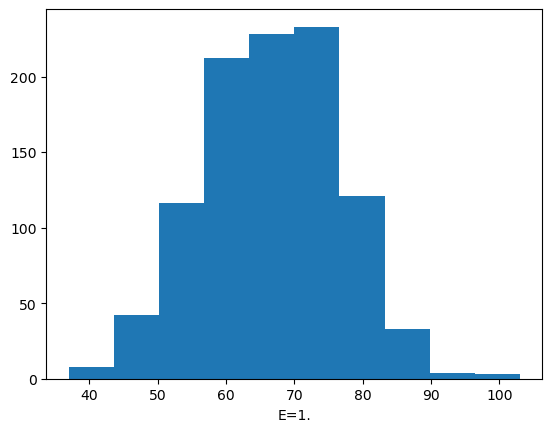

In [1]:
import numpy as np
import random
import math
import matplotlib.pyplot as plt
vector3 = np.ndarray
class Source:
    def __init__(self, Y: float) -> vector3:
        self.Y = Y
    def initgen(self,E:float):
        """ E - энергия """
        nphot = int(round(self.Y * E))
        phi = np.random.uniform(0.0, 2.0 * np.pi, nphot)
        cos_theta = np.random.uniform(-1.0, 1.0, nphot)
        sin_theta = np.sqrt(1.0 - cos_theta ** 2)
        return np.array([sin_theta * np.cos(phi), sin_theta * np.sin(phi),cos_theta])
    
class Detector: 
    def __init__(self, R: float, N: int, r: float, a: float):
        """
        Рассмотрим сферический детектор радиусом R, заполненный
        сцинтиллирующей жидкостью.
        В сцинтилляторе свет от взаимодействия частиц излучается изотропно,
        выход фотонов для события с энергией 1 МэВ равен Y.
        Внутренняя поверхность детектора покрыта N фотоумножителями,
        улавливающими свет от взаимодействия частиц. Считаем, что у
        фотоумножителя плоский фотокатод радиусом r. Bероятность выбивания
        хотя бы одного фотоэлектрона равна a.
        Каждому фотоумножителю соответствует канал набора данных,
        сохраняющий число фотоэлектронов.

        """
        self.R = R 
        self.N = N
        self.r = r
        self.a = a
    def isEMT(self,x,y,EMTlist):
        EMT_angle=np.arcsin(self.r/self.R)
        for centre_coords in EMTlist:
            x_0,y_0=centre_coords
            
            distance=np.sqrt((x-x_0)**2+(y-y_0)**2) #так можно делать, тк радиус ФЭУ много меньше радиуса сферы(но можно переделать под сферическую метрику)
            
            if(distance < EMT_angle):
                return(True)
        return(False)
    def isphotonEMT(self,x,y,z,nx,ny,nz,EMTlist):
        def sf(x,y,z):
            r=np.sqrt(x**2 +y**2 + z**2)
            if math.isclose(x,0.) and math.isclose(y,0.):
                phi=0.
            else:
                phi=np.arctan(y/x)
            theta=np.arccos(z/r)
            return(phi,theta)
        B=2.*(x*nx+y*ny+z*nz)
        C=x**2 + y**2 +z**2 -(self.R)**2
        D=B**2-4.*C
        t1=(-B+np.sqrt(D))/2.
        t2=(-B-np.sqrt(D))/2.
        if (t1>t2):
            t=t1
        else:
            t=t2
        x_=x+t*nx
        y_=y+t*ny
        z_=z+t*nz
        phi,theta=sf(x_,y_,z_)
        answer=self.isEMT(phi,theta,EMTlist)
        return answer
    def elecgain(self,x,y,z,nx,ny,nz,EMTlist,a):
        if self.isphotonEMT(x,y,z,nx,ny,nz,EMTlist)==False:
            return(0.)
        else:
            rng = np.random.default_rng() 
            scalar = rng.poisson(lam=a)
            return(scalar)
''' я добавила этот метод в класс детектора по двум причинам
1. это логично, тк электроны выбиваются в детекторе
2. удобно использовать в методе методы именно класса детектор, потом можно сразу вызывать только метод elecgain
'''
        
                
        

''' для простоты координаты точек на поверхности детектора
и центров ФЭУ будем задавать в сферической системе координат в радианах
координаты phi, theta'''
R = 2
N = 40
r = 0.1
a = 0.5
EMTlist=[]
for i in range(20):
    pgen=float(i)*(360./20.)*np.pi/180.
    tgen = np.pi/2.
    EMTlist.append((pgen, tgen)) 
for i in range(10):
    pgen=float(i)*(360./10.)*np.pi/180.
    tgen = 70.*np.pi/180.
    EMTlist.append((pgen, tgen))
for i in range(10):
    pgen=float(i)*(360./10.)*np.pi/180.
    tgen = 50.*np.pi/180.
    EMTlist.append((pgen, tgen))

det=Detector(R,N,r,a)
surs=Source(10000.)
nevent=1000
sum_elec_list=[]
for j in range(nevent):
    nx,ny,nz=surs.initgen(1.)
    sum_elec=0.
    nphot=len(nx)
    for i in range(nphot):
        sum_elec=sum_elec+det.elecgain(0.,0.,0.,nx[i],ny[i],nz[i],EMTlist,a)
    sum_elec_list.append(sum_elec)
plt.hist(sum_elec_list)
plt.xlabel('E=1.')
plt.show()

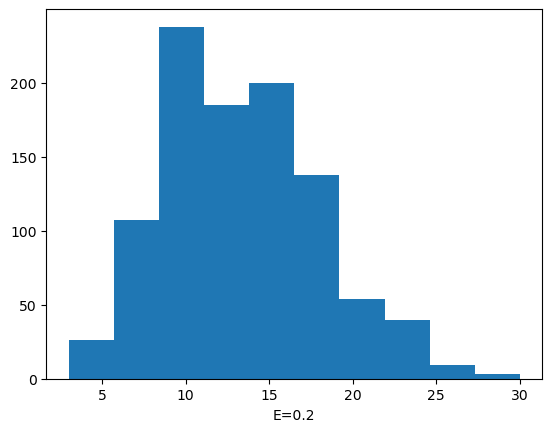

In [2]:
sum_elec_list=[]
for j in range(nevent):
    nx,ny,nz=surs.initgen(0.2)
    sum_elec=0.
    nphot=len(nx)
    for i in range(nphot):
        sum_elec=sum_elec+det.elecgain(0.,0.,0.,nx[i],ny[i],nz[i],EMTlist,a)
    sum_elec_list.append(sum_elec)
plt.hist(sum_elec_list)
plt.xlabel('E=0.2')
plt.show()

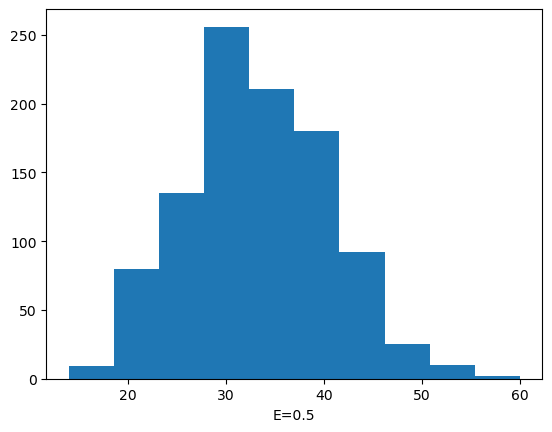

In [3]:
sum_elec_list=[]
for j in range(nevent):
    nx,ny,nz=surs.initgen(0.5)
    sum_elec=0.
    nphot=len(nx)
    for i in range(nphot):
        sum_elec=sum_elec+det.elecgain(0.,0.,0.,nx[i],ny[i],nz[i],EMTlist,a)
    sum_elec_list.append(sum_elec)
plt.hist(sum_elec_list)
plt.xlabel('E=0.5')
plt.show()

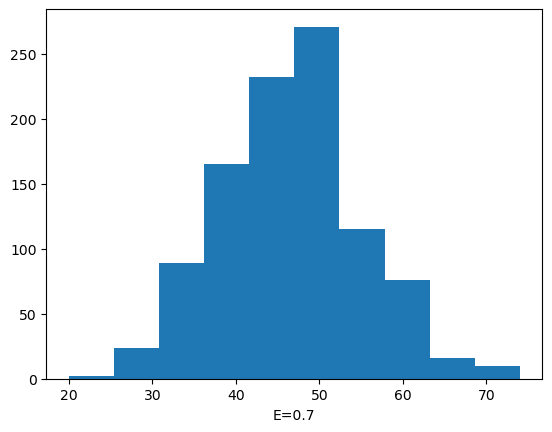

In [4]:
sum_elec_list=[]
for j in range(nevent):
    nx,ny,nz=surs.initgen(0.7)
    sum_elec=0.
    nphot=len(nx)
    for i in range(nphot):
        sum_elec=sum_elec+det.elecgain(0.,0.,0.,nx[i],ny[i],nz[i],EMTlist,a)
    sum_elec_list.append(sum_elec)
plt.hist(sum_elec_list)
plt.xlabel('E=0.7')
plt.show()

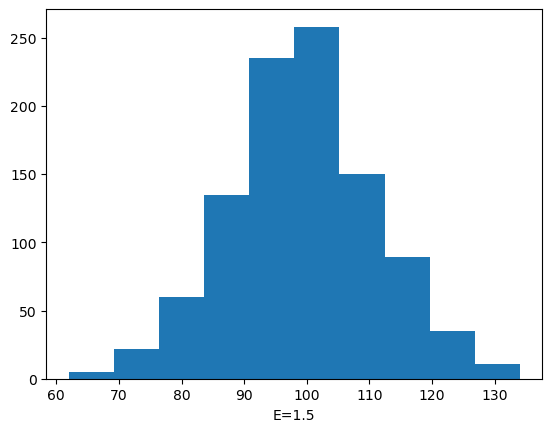

In [5]:
sum_elec_list=[]
for j in range(nevent):
    nx,ny,nz=surs.initgen(1.5)
    sum_elec=0.
    nphot=len(nx)
    for i in range(nphot):
        sum_elec=sum_elec+det.elecgain(0.,0.,0.,nx[i],ny[i],nz[i],EMTlist,a)
    sum_elec_list.append(sum_elec)
plt.hist(sum_elec_list)
plt.xlabel('E=1.5')
plt.show()

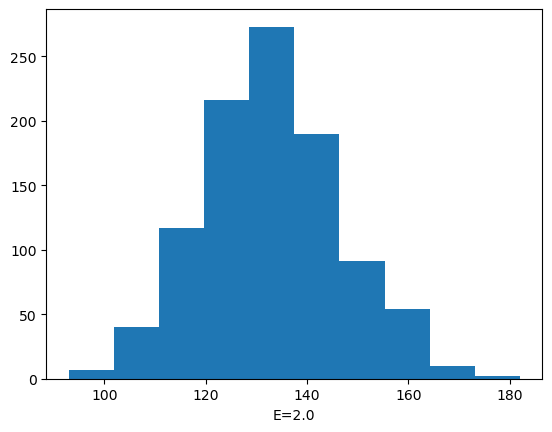

In [2]:
import numpy as np
import random
import math
import matplotlib.pyplot as plt
vector3 = np.ndarray
class Source:
    def __init__(self, Y: float) -> vector3:
        self.Y = Y
    def initgen(self,E:float):
        """ E - энергия """
        nphot = int(round(self.Y * E))
        phi = np.random.uniform(0.0, 2.0 * np.pi, nphot)
        cos_theta = np.random.uniform(-1.0, 1.0, nphot)
        sin_theta = np.sqrt(1.0 - cos_theta ** 2)
        return np.array([sin_theta * np.cos(phi), sin_theta * np.sin(phi),cos_theta])
    
class Detector: 
    def __init__(self, R: float, N: int, r: float, a: float):
        """
        Рассмотрим сферический детектор радиусом R, заполненный
        сцинтиллирующей жидкостью.
        В сцинтилляторе свет от взаимодействия частиц излучается изотропно,
        выход фотонов для события с энергией 1 МэВ равен Y.
        Внутренняя поверхность детектора покрыта N фотоумножителями,
        улавливающими свет от взаимодействия частиц. Считаем, что у
        фотоумножителя плоский фотокатод радиусом r. Bероятность выбивания
        хотя бы одного фотоэлектрона равна a.
        Каждому фотоумножителю соответствует канал набора данных,
        сохраняющий число фотоэлектронов.

        """
        self.R = R 
        self.N = N
        self.r = r
        self.a = a
    def isEMT(self,x,y,EMTlist):
        EMT_angle=np.arcsin(self.r/self.R)
        for centre_coords in EMTlist:
            x_0,y_0=centre_coords
            
            distance=np.sqrt((x-x_0)**2+(y-y_0)**2) #так можно делать, тк радиус ФЭУ много меньше радиуса сферы(но можно переделать под сферическую метрику)
            
            if(distance < EMT_angle):
                return(True)
        return(False)
    def isphotonEMT(self,x,y,z,nx,ny,nz,EMTlist):
        def sf(x,y,z):
            r=np.sqrt(x**2 +y**2 + z**2)
            if math.isclose(x,0.) and math.isclose(y,0.):
                phi=0.
            else:
                phi=np.arctan(y/x)
            theta=np.arccos(z/r)
            return(phi,theta)
        B=2.*(x*nx+y*ny+z*nz)
        C=x**2 + y**2 +z**2 -(self.R)**2
        D=B**2-4.*C
        t1=(-B+np.sqrt(D))/2.
        t2=(-B-np.sqrt(D))/2.
        if (t1>t2):
            t=t1
        else:
            t=t2
        x_=x+t*nx
        y_=y+t*ny
        z_=z+t*nz
        phi,theta=sf(x_,y_,z_)
        answer=self.isEMT(phi,theta,EMTlist)
        return answer
    def elecgain(self,x,y,z,nx,ny,nz,EMTlist,a):
        if self.isphotonEMT(x,y,z,nx,ny,nz,EMTlist)==False:
            return(0.)
        else:
            rng = np.random.default_rng() 
            scalar = rng.poisson(lam=a)
            return(scalar)
''' я добавила этот метод в класс детектора по двум причинам
1. это логично, тк электроны выбиваются в детекторе
2. удобно использовать в методе методы именно класса детектор, потом можно сразу вызывать только метод elecgain
'''
        
                
        

''' для простоты координаты точек на поверхности детектора
и центров ФЭУ будем задавать в сферической системе координат в радианах
координаты phi, theta'''
R = 2
N = 40
r = 0.1
a = 0.5
EMTlist=[]
for i in range(20):
    pgen=float(i)*(360./20.)*np.pi/180.
    tgen = np.pi/2.
    EMTlist.append((pgen, tgen)) 
for i in range(10):
    pgen=float(i)*(360./10.)*np.pi/180.
    tgen = 70.*np.pi/180.
    EMTlist.append((pgen, tgen))
for i in range(10):
    pgen=float(i)*(360./10.)*np.pi/180.
    tgen = 50.*np.pi/180.
    EMTlist.append((pgen, tgen))

det=Detector(R,N,r,a)
surs=Source(10000.)
nevent=1000
sum_elec_list=[]
for j in range(nevent):
    nx,ny,nz=surs.initgen(2.0)
    sum_elec=0.
    nphot=len(nx)
    for i in range(nphot):
        sum_elec=sum_elec+det.elecgain(0.,0.,0.,nx[i],ny[i],nz[i],EMTlist,a)
    sum_elec_list.append(sum_elec)
plt.hist(sum_elec_list)
plt.xlabel('E=2.0')
plt.show()

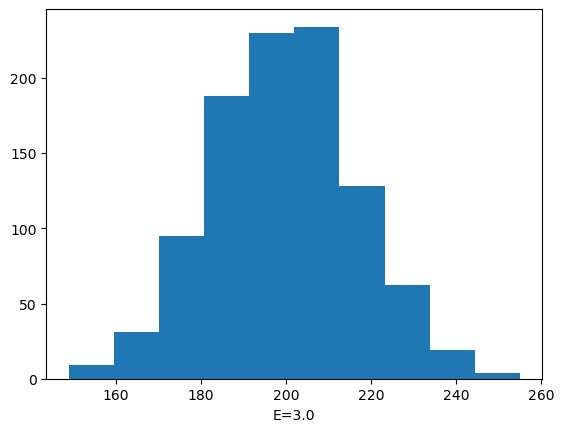

In [3]:
sum_elec_list=[]
for j in range(nevent):
    nx,ny,nz=surs.initgen(3.0)
    sum_elec=0.
    nphot=len(nx)
    for i in range(nphot):
        sum_elec=sum_elec+det.elecgain(0.,0.,0.,nx[i],ny[i],nz[i],EMTlist,a)
    sum_elec_list.append(sum_elec)
plt.hist(sum_elec_list)
plt.xlabel('E=3.0')
plt.show()

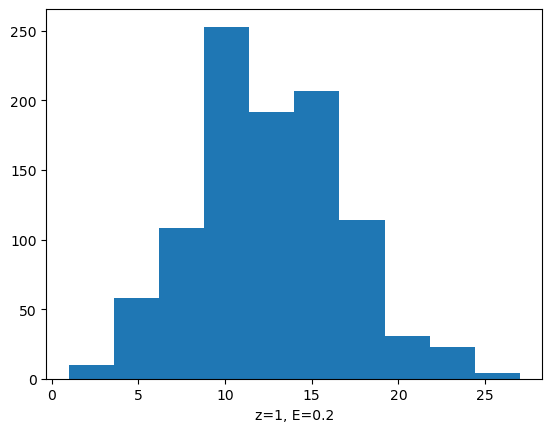

In [4]:
sum_elec_list=[]
for j in range(nevent):
    nx,ny,nz=surs.initgen(0.2)
    sum_elec=0.
    nphot=len(nx)
    for i in range(nphot):
        sum_elec=sum_elec+det.elecgain(0.,0.,1.,nx[i],ny[i],nz[i],EMTlist,a)
    sum_elec_list.append(sum_elec)
plt.hist(sum_elec_list)
plt.xlabel('z=1, E=0.2')
plt.show()

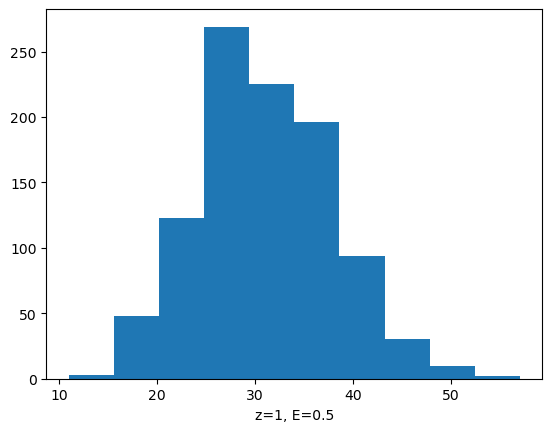

In [5]:
sum_elec_list=[]
for j in range(nevent):
    nx,ny,nz=surs.initgen(0.5)
    sum_elec=0.
    nphot=len(nx)
    for i in range(nphot):
        sum_elec=sum_elec+det.elecgain(0.,0.,1.,nx[i],ny[i],nz[i],EMTlist,a)
    sum_elec_list.append(sum_elec)
plt.hist(sum_elec_list)
plt.xlabel('z=1, E=0.5')
plt.show()

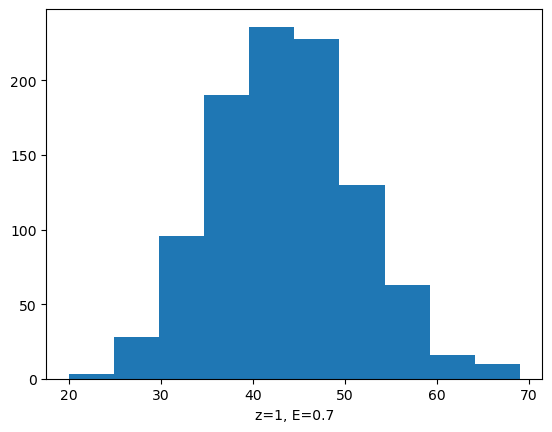

In [6]:
sum_elec_list=[]
for j in range(nevent):
    nx,ny,nz=surs.initgen(0.7)
    sum_elec=0.
    nphot=len(nx)
    for i in range(nphot):
        sum_elec=sum_elec+det.elecgain(0.,0.,1.,nx[i],ny[i],nz[i],EMTlist,a)
    sum_elec_list.append(sum_elec)
plt.hist(sum_elec_list)
plt.xlabel('z=1, E=0.7')
plt.show()

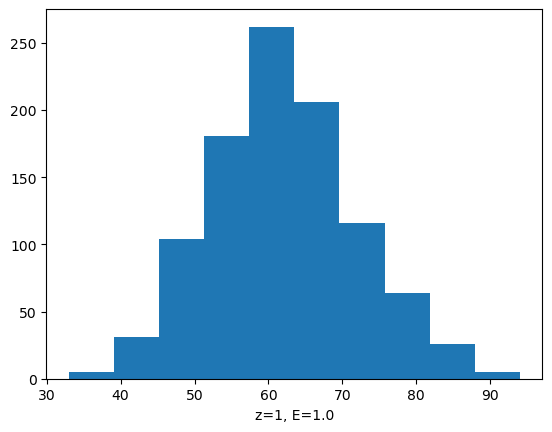

In [7]:
sum_elec_list=[]
for j in range(nevent):
    nx,ny,nz=surs.initgen(1.0)
    sum_elec=0.
    nphot=len(nx)
    for i in range(nphot):
        sum_elec=sum_elec+det.elecgain(0.,0.,1.,nx[i],ny[i],nz[i],EMTlist,a)
    sum_elec_list.append(sum_elec)
plt.hist(sum_elec_list)
plt.xlabel('z=1, E=1.0')
plt.show()

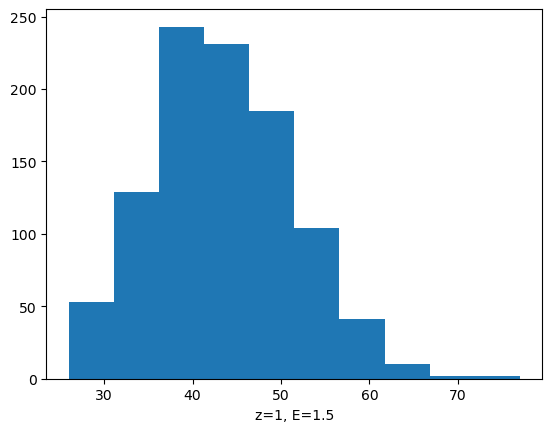

In [8]:
sum_elec_list=[]
for j in range(nevent):
    nx,ny,nz=surs.initgen(0.7)
    sum_elec=0.
    nphot=len(nx)
    for i in range(nphot):
        sum_elec=sum_elec+det.elecgain(0.,0.,1.,nx[i],ny[i],nz[i],EMTlist,a)
    sum_elec_list.append(sum_elec)
plt.hist(sum_elec_list)
plt.xlabel('z=1, E=1.5')
plt.show()

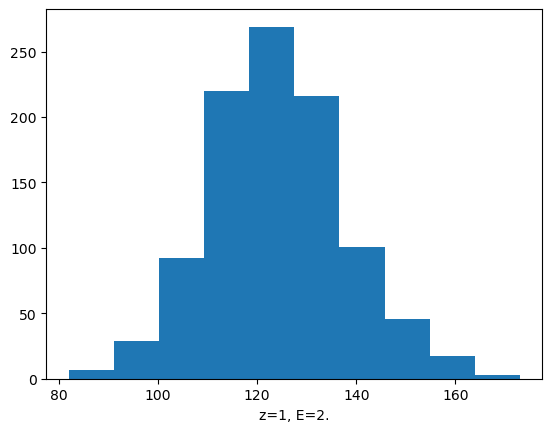

In [9]:
sum_elec_list=[]
for j in range(nevent):
    nx,ny,nz=surs.initgen(2.)
    sum_elec=0.
    nphot=len(nx)
    for i in range(nphot):
        sum_elec=sum_elec+det.elecgain(0.,0.,1.,nx[i],ny[i],nz[i],EMTlist,a)
    sum_elec_list.append(sum_elec)
plt.hist(sum_elec_list)
plt.xlabel('z=1, E=2.')
plt.show()

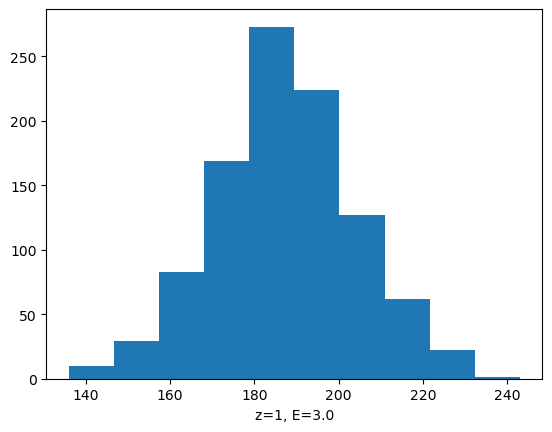

In [10]:
sum_elec_list=[]
for j in range(nevent):
    nx,ny,nz=surs.initgen(3.0)
    sum_elec=0.
    nphot=len(nx)
    for i in range(nphot):
        sum_elec=sum_elec+det.elecgain(0.,0.,1.,nx[i],ny[i],nz[i],EMTlist,a)
    sum_elec_list.append(sum_elec)
plt.hist(sum_elec_list)
plt.xlabel('z=1, E=3.0')
plt.show()